In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import smarts_cerebellum.globals as gl

segment = 'GM'

# patients_actual means
patients_actual = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}', f'summary_MNISymC_pons_{segment}_mod.tsv'), sep = '\t')
patients_actual = patients_actual[patients_actual.isPatient == 1]
patients_actual = patients_actual.groupby(['Week', 'regionname'])['mean'].mean().reset_index()

# pred means
patients_lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', f'patients_MNISymC_{segment}_mod_pons_lme.tsv'), sep = '\t')
patients_lme = patients_lme.drop(columns = ['subj_id', 'random_intercept', 'Unnamed: 0']).drop_duplicates().reset_index(drop = True)

# get hemisphere
patients_lme['hemisphere'] = patients_lme.regionname.str[-1].str.lower()
patients_actual['hemisphere'] = patients_actual.regionname.str[-1].str.lower()

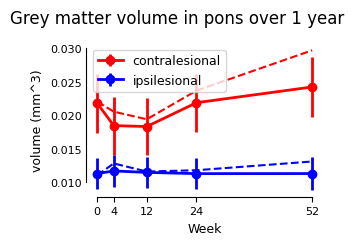

In [10]:
colours = ['green', 'r', 'blue']

fig, ax = plt.subplots( figsize=(3,2), sharey = True, constrained_layout=True)

for i, H in enumerate(['l', 'r']):


    patients_lme_h    = patients_lme[patients_lme.hemisphere == H].sort_values('Week')
    patients_actual_h = patients_actual[patients_actual.hemisphere == H].sort_values('Week')


    ax.errorbar(x=patients_lme_h['Week'], y=patients_lme_h['beta'], yerr = patients_lme_h['se'], fmt = '-o', color = colours[i+1], linewidth = 2, 
                label = 'ipsilesional' if H == 'r' else 'contralesional')
    ax.plot(patients_actual_h['Week'], patients_actual_h['mean'], color = colours[i+1], linestyle = '--')


for i in range(2):
    ax.set_xticks(gl.weeks)
    ax.set_xlabel("Week")
    #ax.set_ylim(.52, .66*1.05)

# remove ticks for all plots except first on y-axis
ax.tick_params(axis = 'y', length = 0)

ax.set_ylabel('volume (mm^3)')
fig.suptitle('Grey matter volume in pons over 1 year', y = 1.15)
plt.legend()
sns.despine(trim = True)

plt.show()